In [1]:
# path

# 1.Population dynamics

##   Control — vertical transmission only

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

Control CSV files found: 10


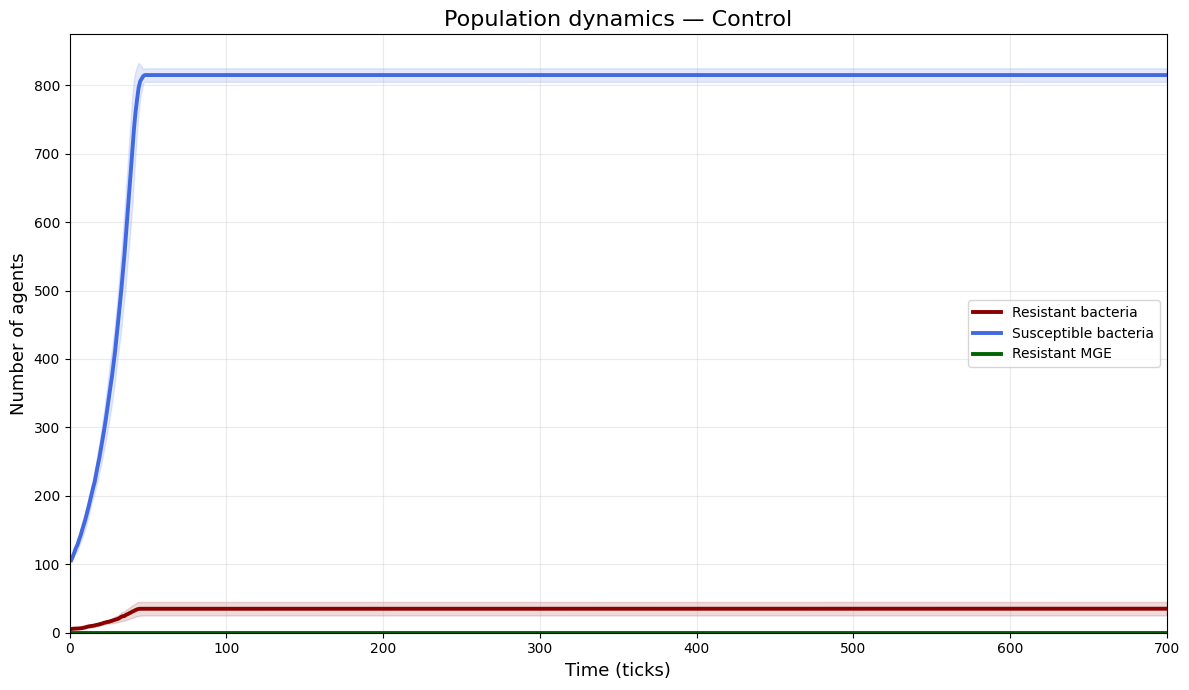

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Folder containing Control CSV files
folder = "../data/control"
files = sorted(
    filename for filename in os.listdir(folder)
    if filename.lower().endswith(".csv")
)

print("Control CSV files found:", len(files))

columns = [
    "ticks",
    "resistant_bacteria",
    "susceptible_bacteria",
    "resistant_MGE"
]

replicas = []

for filename in files:
    file = folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")
    df = df.set_index("ticks")

    replicas.append(df)

if len(replicas) == 0:
    raise ValueError("No Control CSV files were found. Check ../data/control")

data = pd.concat(replicas, axis=1, keys=range(len(replicas)))

plt.figure(figsize=(12, 7))

colors = {
    "resistant_bacteria": "darkred",
    "susceptible_bacteria": "royalblue",
    "resistant_MGE": "darkgreen"
}

labels = {
    "resistant_bacteria": "Resistant bacteria",
    "susceptible_bacteria": "Susceptible bacteria",
    "resistant_MGE": "Resistant MGE"
}

for metric in columns[1:]:
    values = data.xs(metric, axis=1, level=1)
    mean = values.mean(axis=1)
    std = values.std(axis=1)

    plt.plot(
        mean.index, mean,
        color=colors[metric],
        linewidth=2.8,
        label=labels[metric]
    )

    plt.fill_between(
        mean.index,
        mean - std,
        mean + std,
        color=colors[metric],
        alpha=0.14
    )

plt.title("Population dynamics — Control", fontsize=16)
plt.xlabel("Time (ticks)", fontsize=13)
plt.ylabel("Number of agents", fontsize=13)
plt.xlim(0, 700)
plt.ylim(bottom=0)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("population_dynamics_control.png", dpi=300)
plt.show()

# Experiment — Vertical + Horizontal Transmission

Experiment CSV files found: 10


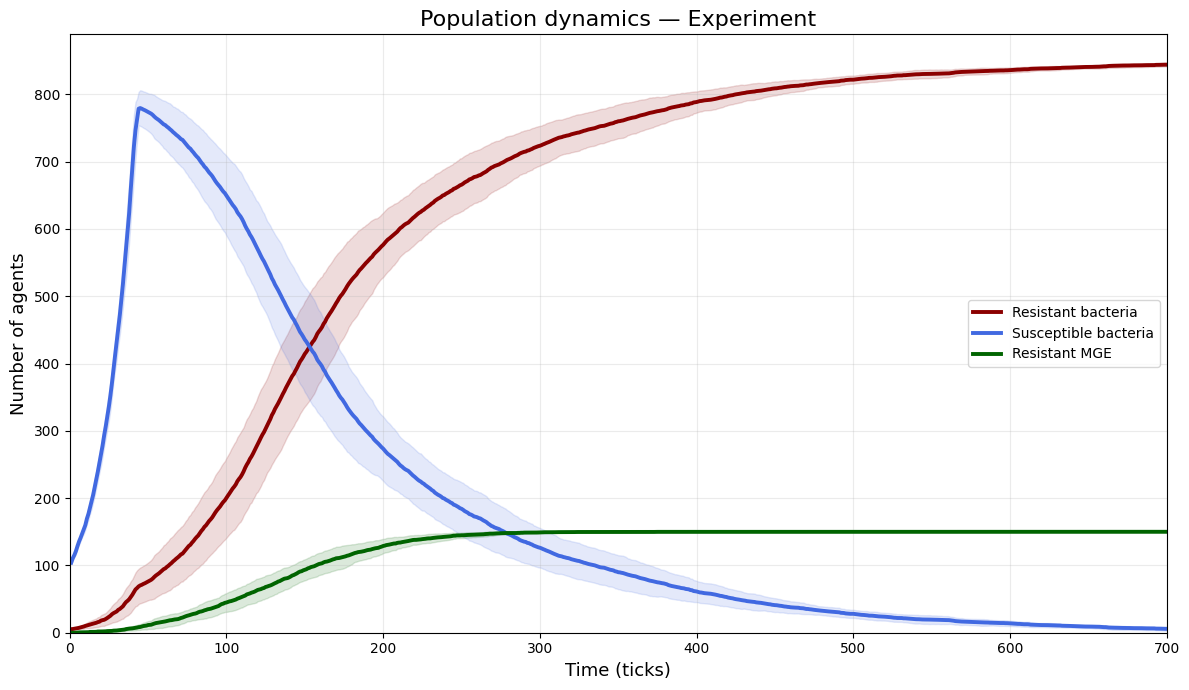

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Folder containing Experiment CSV files
folder = "../data/experiment"
files = sorted(
    filename for filename in os.listdir(folder)
    if filename.lower().endswith(".csv")
)

print("Experiment CSV files found:", len(files))

columns = [
    "ticks",
    "resistant_bacteria",
    "susceptible_bacteria",
    "resistant_MGE"
]

replicas = []

for filename in files:
    file = folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")
    df = df.set_index("ticks")

    replicas.append(df)

if len(replicas) == 0:
    raise ValueError("No Experiment CSV files were found. Check ../data/experiment")

data = pd.concat(replicas, axis=1, keys=range(len(replicas)))

plt.figure(figsize=(12, 7))

colors = {
    "resistant_bacteria": "darkred",
    "susceptible_bacteria": "royalblue",
    "resistant_MGE": "darkgreen"
}

labels = {
    "resistant_bacteria": "Resistant bacteria",
    "susceptible_bacteria": "Susceptible bacteria",
    "resistant_MGE": "Resistant MGE"
}

for metric in columns[1:]:
    values = data.xs(metric, axis=1, level=1)
    mean = values.mean(axis=1)
    std = values.std(axis=1)

    plt.plot(
        mean.index, mean,
        color=colors[metric],
        linewidth=2.8,
        label=labels[metric]
    )

    plt.fill_between(
        mean.index,
        mean - std,
        mean + std,
        color=colors[metric],
        alpha=0.14
    )

plt.title("Population dynamics — Experiment", fontsize=16)
plt.xlabel("Time (ticks)", fontsize=13)
plt.ylabel("Number of agents", fontsize=13)
plt.xlim(0, 700)
plt.ylim(bottom=0)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("population_dynamics_experiment.png", dpi=300)
plt.show()

# Comparison of resistant bacteria.

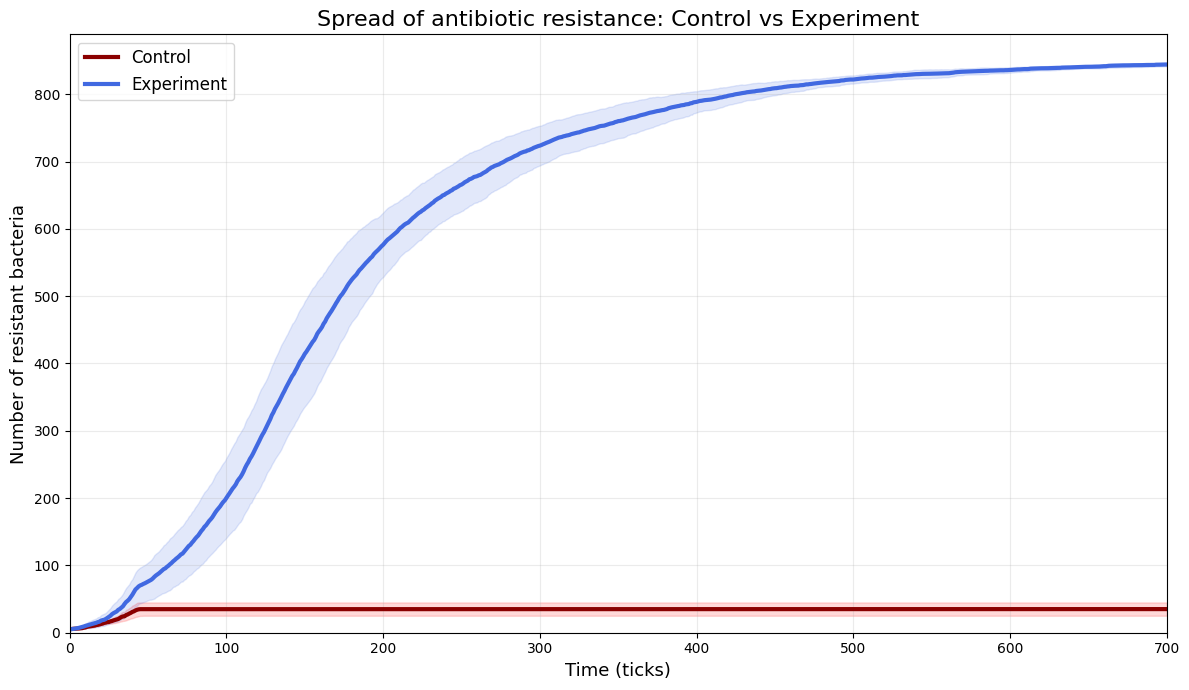

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import os

columns = [
    "ticks",
    "resistant_bacteria",
    "susceptible_bacteria",
    "resistant_MGE"
]

# 1. Read Control data
control_folder = "../data/control"
control_files = sorted(
    filename for filename in os.listdir(control_folder)
    if filename.lower().endswith(".csv")
)

control_data = []

for filename in control_files:
    file = control_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")
    df = df.set_index("ticks")

    control_data.append(df["resistant_bacteria"])

if len(control_data) == 0:
    raise ValueError("No Control CSV files found in ../data/control")

control_data = pd.concat(control_data, axis=1)

# 2. Read Experiment data
experiment_folder = "../data/experiment"
experiment_files = sorted(
    filename for filename in os.listdir(experiment_folder)
    if filename.lower().endswith(".csv")
)

experiment_data = []

for filename in experiment_files:
    file = experiment_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")
    df = df.set_index("ticks")

    experiment_data.append(df["resistant_bacteria"])

if len(experiment_data) == 0:
    raise ValueError("No Experiment CSV files found in ../data/experiment")

experiment_data = pd.concat(experiment_data, axis=1)

# 3. Calculate mean and standard deviation
control_mean = control_data.mean(axis=1)
control_std = control_data.std(axis=1)
experiment_mean = experiment_data.mean(axis=1)
experiment_std = experiment_data.std(axis=1)

# 4. Plot comparison
plt.figure(figsize=(12, 7))

plt.plot(
    control_mean.index, control_mean,
    color="darkred", linewidth=3, label="Control"
)
plt.fill_between(
    control_mean.index,
    control_mean - control_std,
    control_mean + control_std,
    color="red", alpha=0.15
)

plt.plot(
    experiment_mean.index, experiment_mean,
    color="royalblue", linewidth=3, label="Experiment"
)
plt.fill_between(
    experiment_mean.index,
    experiment_mean - experiment_std,
    experiment_mean + experiment_std,
    color="royalblue", alpha=0.15
)

plt.title("Spread of antibiotic resistance: Control vs Experiment", fontsize=16)
plt.xlabel("Time (ticks)", fontsize=13)
plt.ylabel("Number of resistant bacteria", fontsize=13)
plt.xlim(0, 700)
plt.ylim(bottom=0)
plt.legend(fontsize=12)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("resistant_bacteria_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Control runs: 10
Experiment runs: 10
Control values: [np.int64(29), np.int64(38), np.int64(22), np.int64(43), np.int64(51), np.int64(28), np.int64(42), np.int64(28), np.int64(45), np.int64(25)]
Experiment values: [np.int64(844), np.int64(838), np.int64(844), np.int64(845), np.int64(847), np.int64(846), np.int64(843), np.int64(842), np.int64(847), np.int64(846)]


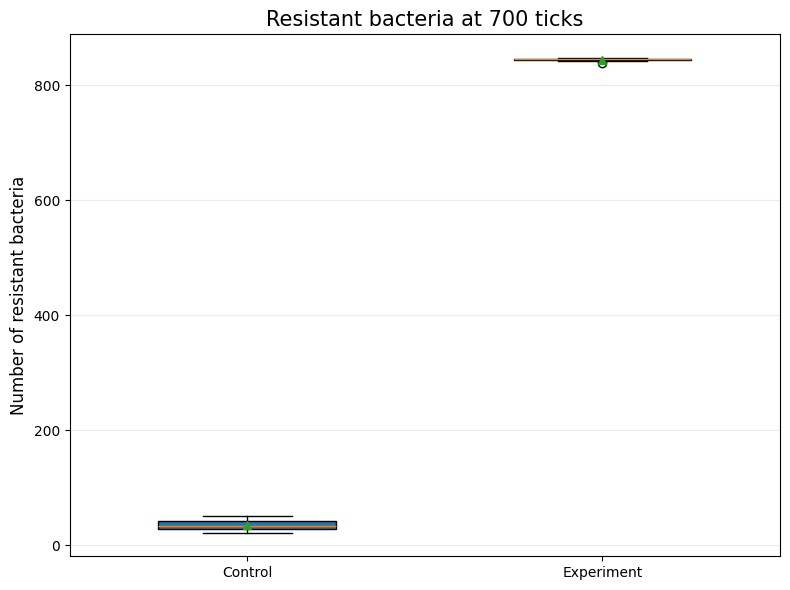

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os

columns = [
    "ticks",
    "resistant_bacteria",
    "susceptible_bacteria",
    "resistant_MGE"
]

# 1. Load Control values at tick 700
control_folder = "../data/control"
control_files = sorted(
    filename for filename in os.listdir(control_folder)
    if filename.lower().endswith(".csv")
)

control_values = []

for filename in control_files:
    file = control_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df["ticks"] = pd.to_numeric(df["ticks"], errors="coerce")
    df["resistant_bacteria"] = pd.to_numeric(
        df["resistant_bacteria"], errors="coerce"
    )

    value = df.loc[df["ticks"] == 700, "resistant_bacteria"]
    if not value.empty:
        control_values.append(value.iloc[-1])

# 2. Load Experiment values at tick 700
experiment_folder = "../data/experiment"
experiment_files = sorted(
    filename for filename in os.listdir(experiment_folder)
    if filename.lower().endswith(".csv")
)

experiment_values = []

for filename in experiment_files:
    file = experiment_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df["ticks"] = pd.to_numeric(df["ticks"], errors="coerce")
    df["resistant_bacteria"] = pd.to_numeric(
        df["resistant_bacteria"], errors="coerce"
    )

    value = df.loc[df["ticks"] == 700, "resistant_bacteria"]
    if not value.empty:
        experiment_values.append(value.iloc[-1])

# 3. Check data
print("Control runs:", len(control_values))
print("Experiment runs:", len(experiment_values))
print("Control values:", control_values)
print("Experiment values:", experiment_values)

# 4. Create boxplot
plt.figure(figsize=(8, 6))
plt.boxplot(
    [control_values, experiment_values],
    tick_labels=["Control", "Experiment"],
    patch_artist=True,
    widths=0.5,
    showmeans=True
)

plt.title("Resistant bacteria at 700 ticks", fontsize=15)
plt.ylabel("Number of resistant bacteria", fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("boxplot_resistant_bacteria.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
import pandas as pd
import numpy as np
import os
from scipy import stats

# Settings
columns = [
    "ticks",
    "resistant_bacteria",
    "susceptible_bacteria",
    "resistant_MGE"
]
target_tick = 700

# 1. Load Control data
control_folder = "../data/control"
control_files = sorted(
    filename for filename in os.listdir(control_folder)
    if filename.lower().endswith(".csv")
)

control_results = []

for filename in control_files:
    file = control_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")

    result = df[df["ticks"] == target_tick]
    if result.empty:
        print("WARNING:", filename, "- tick 700 missing")
        continue

    row = result.iloc[-1]
    resistant = row["resistant_bacteria"]
    susceptible = row["susceptible_bacteria"]
    total = resistant + susceptible

    control_results.append({
        "Scenario": "Control",
        "Resistant bacteria": resistant,
        "Susceptible bacteria": susceptible,
        "Resistant MGE": row["resistant_MGE"],
        "Total bacteria": total,
        "Resistant proportion (%)":
            resistant / total * 100 if total > 0 else np.nan
    })

# 2. Load Experiment data
experiment_folder = "../data/experiment"
experiment_files = sorted(
    filename for filename in os.listdir(experiment_folder)
    if filename.lower().endswith(".csv")
)

experiment_results = []

for filename in experiment_files:
    file = experiment_folder + "/" + filename
    df = pd.read_csv(file, header=None)

    if str(df.iloc[0, 0]).lower() == "ticks":
        df = df.iloc[1:]

    df = df.iloc[:, :4]
    df.columns = columns
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    df = df.drop_duplicates("ticks")

    result = df[df["ticks"] == target_tick]
    if result.empty:
        print("WARNING:", filename, "- tick 700 missing")
        continue

    row = result.iloc[-1]
    resistant = row["resistant_bacteria"]
    susceptible = row["susceptible_bacteria"]
    total = resistant + susceptible

    experiment_results.append({
        "Scenario": "Experiment",
        "Resistant bacteria": resistant,
        "Susceptible bacteria": susceptible,
        "Resistant MGE": row["resistant_MGE"],
        "Total bacteria": total,
        "Resistant proportion (%)":
            resistant / total * 100 if total > 0 else np.nan
    })

# 3. Combine results
data = pd.DataFrame(control_results + experiment_results)

print("Number of Control runs:", len(control_results))
print("Number of Experiment runs:", len(experiment_results))
print("\nIndividual results:")
display(data)

# 4. Descriptive statistics
metrics = [
    "Resistant bacteria",
    "Susceptible bacteria",
    "Resistant MGE",
    "Total bacteria",
    "Resistant proportion (%)"
]

summary = data.groupby("Scenario")[metrics].agg(
    ["count", "mean", "std", "median", "min", "max"]
)

print("\nDESCRIPTIVE STATISTICS")
display(summary.round(2))

# 5. Statistical comparison: Welch's t-test and Cohen's d
comparison_results = []

for metric in metrics:
    control = data.loc[data["Scenario"] == "Control", metric].dropna().values
    experiment = data.loc[data["Scenario"] == "Experiment", metric].dropna().values

    if len(control) < 2 or len(experiment) < 2:
        continue

    t_stat, p_value = stats.ttest_ind(
        experiment, control, equal_var=False
    )

    difference = np.mean(experiment) - np.mean(control)

    percentage_change = (
        difference / np.mean(control) * 100
        if np.mean(control) != 0 else np.nan
    )

    pooled_sd = np.sqrt(
        (
            (len(control) - 1) * np.var(control, ddof=1)
            + (len(experiment) - 1) * np.var(experiment, ddof=1)
        )
        / (len(control) + len(experiment) - 2)
    )

    cohens_d = difference / pooled_sd if pooled_sd > 0 else np.nan

    comparison_results.append({
        "Metric": metric,
        "Control mean": np.mean(control),
        "Experiment mean": np.mean(experiment),
        "Difference": difference,
        "Change (%)": percentage_change,
        "t-statistic": t_stat,
        "p-value": p_value,
        "Cohen's d": cohens_d
    })

comparison = pd.DataFrame(comparison_results)

print("\nSTATISTICAL COMPARISON")
display(comparison.round(4))

# 6. Export tables
data.to_csv("individual_results.csv", index=False)
summary.to_csv("descriptive_statistics.csv")
comparison.to_csv("statistical_comparison.csv", index=False)

print("\nThree CSV files saved successfully:")
print("1. individual_results.csv")
print("2. descriptive_statistics.csv")
print("3. statistical_comparison.csv")

Number of Control runs: 10
Number of Experiment runs: 10

Individual results:


,Scenario,Resistant bacteria,Susceptible bacteria,Resistant MGE,Total bacteria,Resistant proportion (%)
0,Control,29,821,0,850,3.411765
1,Control,38,812,0,850,4.470588
2,Control,22,828,0,850,2.588235
3,Control,43,807,0,850,5.058824
4,Control,51,799,0,850,6.000000
5,Control,28,822,0,850,3.294118
6,Control,42,808,0,850,4.941176
7,Control,28,822,0,850,3.294118
8,Control,45,805,0,850,5.294118
9,Control,25,825,0,850,2.941176



DESCRIPTIVE STATISTICS


Resistant bacteria                                \
                        count   mean   std median  min  max   
Scenario                                                      
Control                    10   35.1  9.89   33.5   22   51   
Experiment                 10  844.2  2.74  844.5  838  847   

           Susceptible bacteria                      ... Total bacteria  \
                          count   mean   std median  ...            std   
Scenario                                             ...                  
Control                      10  814.9  9.89  816.5  ...            0.0   
Experiment                   10    5.8  2.74    5.5  ...            0.0   

                            Resistant proportion (%)                      \
           median  min  max                    count   mean   std median   
Scenario                                                                   
Control     850.0  850  850                       10   4.13  1.16   3.94   
Experiment  850.0  850  850                       10  99.32  0.32  99.35   

                          
              min    max  
Scenario                  
Control      2.59   6.00  
Experiment  98.59  99.65  

[2 rows x 30 columns]


STATISTICAL COMPARISON


R:\anaconda\envs\bio_smi\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
R:\anaconda\envs\bio_smi\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,Metric,Control mean,Experiment mean,Difference,Change (%),t-statistic,p-value,Cohen's d
0,Resistant bacteria,35.1000,844.2000,809.1000,2305.1282,249.2326,0.0,111.4602
1,Susceptible bacteria,814.9000,5.8000,-809.1000,-99.2883,-249.2326,0.0,-111.4602
2,Resistant MGE,0.0000,150.0000,150.0000,NaN,inf,0.0,NaN
3,Total bacteria,850.0000,850.0000,0.0000,0.0000,NaN,NaN,NaN
4,Resistant proportion (%),4.1294,99.3176,95.1882,2305.1282,249.2326,0.0,111.4602



Three CSV files saved successfully:
1. individual_results.csv
2. descriptive_statistics.csv
3. statistical_comparison.csv


In [21]:
# P value

In [22]:
from scipy import stats

# Welch's t-test for the number of resistant bacteria at tick 700
t_stat, p_value = stats.ttest_ind(
    experiment_values,
    control_values,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)


t-statistic: 249.2325656842924
p-value: 6.191740722647565e-21
